# Pasos para el analisis: obtener y preparar datos desde Hugging Face

**Dataset:** [`aptologia/casa-vs-apartamento-precio-m2-ciudades-colombia-2026`](https://huggingface.co/datasets/aptologia/casa-vs-apartamento-precio-m2-ciudades-colombia-2026)

Precio de oferta por metro cuadrado de casas y apartamentos en 38 ciudades de Colombia (2026). Licencia CC BY 4.0, autor: Aptología.

| Columna | Descripción |
|---|---|
| `city` | Ciudad |
| `n_si` | Conteo asociado a casas (ver nota en la transformación 1) |
| `n_no` | Conteo asociado a apartamentos (ver nota en la transformación 1) |
| `casa_cop_m2` | Precio por m² de casas, en pesos colombianos |
| `apto_cop_m2` | Precio por m² de apartamentos, en pesos colombianos |
| `diferencia_pct` | Diferencia porcentual de la casa frente al apartamento: `(casa / apto − 1) × 100`. Negativo = la casa es más barata |

Flujo del notebook:

```
HFDatasetLoader → DataFrame → transformaciones → Reportes → reportes/vivienda_colombia.txt
```

- **`src/clases_po/hf_loader.py`**: clase `HFDatasetLoader`, se conecta a Hugging Face, devuelve un DataFrame y guarda los datos originales en `datos/`.
- **`src/clases_po/reportes.py`**: clase `Reportes`, recibe un DataFrame y genera el reporte `.txt`.
- **Este notebook**: coordina ambas clases y aplica las transformaciones.

    

# Preguntas de negocio
**Retoma las preguntas de negocio**
1. ¿En qué ciudades de Colombia la tendencia del mercado se invierte y comprar casa resulta más costoso que comprar apartamento?
Utilidad: Permite identificar los municipios atípicos (como El Carmen de Viboral, La Calera o Cajicá) donde las casas superan en precio por metro cuadrado a los apartamentos, usualmente impulsadas por la demanda de vivienda campestre o espacio exclusivo.

2. ¿Cuáles son las ciudades con la mayor brecha de descuento en casas frente a apartamentos, y qué tanto influye la dinámica turística o costera?
Utilidad: Analizar por qué en plazas de alta oferta turística o de playa (como Santa Marta o Cartagena) el metro cuadrado de una casa llega a ser hasta un 45% o 60% más económico que el de un apartamento, contrastando con la densificación vertical de estas zonas.


3. ¿Cómo se comporta el mercado inmobiliario dentro de las principales áreas metropolitanas (por ejemplo, el Valle de Aburrá vs. la Sabana de Bogotá)?
Utilidad: Comparar municipios cercanos a las grandes capitales (como Envigado, Sabaneta, Itagüí, Chía o Cajicá) para determinar si los precios por $m^2$ de apartamentos o casas siguen una tendencia de descentralización o si mantienen una prima alta frente a las capitales principales.

4. ¿Existe una correlación directa entre el volumen de oferta analizado (n_si y n_no) y el nivel de precios del metro cuadrado?
Utilidad: Evaluar si los mercados con mayor liquidez y número de publicaciones listadas (como Bogotá o Medellín con decenas de miles de registros) concentran los valores más altos por metro cuadrado del país en comparación con municipios de menor tamaño muestral.

5. ¿Cuál es la proporción general de costos a escala nacional entre ambas tipologías de vivienda?
Utilidad: Determinar promedios ponderados para saber, a grandes rasgos, cuál es el costo de oportunidad o ahorro porcentual al preferir una casa frente a un apartamento al momento de invertir en finca raíz en Colombia.


## Preparar el entorno e importar las clases y Obtener el DataFrame desde Hugging Face ##
El notebook puede ejecutarse desde distintas carpetas. Por eso se buscan los directorios padres hasta encontrar src/clases_po y se agrega src a sys.path. Así se pueden importar las clases sin instalar el proyecto como paquete.
El dataset tiene un único split, train. Con filename, los datos originales también se guardan como CSV en datos/.

In [4]:
import sys  # Módulo del sistema; permite modificar las rutas donde Python busca módulos
from pathlib import Path  # Para manejar rutas de carpetas
##librerias para graficar
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

ROOT = Path.cwd().resolve()  # Empezamos en la carpeta desde donde se ejecuta el notebook
while ROOT != ROOT.parent and not (ROOT / "src" / "clases_po").exists():  # Mientras no encontremos src/clases_po...
    ROOT = ROOT.parent  # ...subimos una carpeta

sys.path.insert(0, str(ROOT / "src"))  # Agregamos src/ a las rutas de búsqueda de Python

import pandas as pd  # Librería para trabajar con DataFrames
from clases_po import HFDatasetLoader, Reportes  # Importamos las dos clases desde src/clases_po

pd.set_option("display.float_format", "{:,.2f}".format)  # Muestra los decimales con 2 cifras y separador de miles
loader = HFDatasetLoader(  # Creamos el cargador
    dataset_name="aptologia/casa-vs-apartamento-precio-m2-ciudades-colombia-2026",  # Identificador del dataset en Hugging Face
    split="train",  # División a descargar (es la única que tiene)
    filename="datos/vivienda_colombia.csv",  # Copia de los datos originales en CSV
)
df = loader.load()  # Descargamos el dataset y lo obtenemos como DataFrame de pandas
print(loader.info())  # Información básica: dataset, split, filas y columnas
df.head()  # Mostramos las primeras 5 filas para observar los datos (esto NO es una transformación)

{'dataset': 'aptologia/casa-vs-apartamento-precio-m2-ciudades-colombia-2026', 'config': None, 'split': 'train', 'filas': 38, 'columnas': 6}


,city,n_si,n_no,casa_cop_m2,apto_cop_m2,diferencia_pct
0,Santa Marta,1084,3779,"3,490,168.70","8,720,930.23",-59.98
1,Cartagena,1327,5774,"4,296,875.00","7,857,142.86",-45.31
2,Palmira,357,112,"2,453,416.15","4,194,668.20",-41.51
3,Bogotá,17756,31265,"4,686,644.57","7,261,904.76",-35.46
4,Puerto Colombia,139,144,"3,938,115.33","5,867,102.40",-32.88


## Verificamos datos y enrriquecemos el Dataframe ##

In [5]:
# 2. Control de calidad y normalización de textos
df['city'] = df['city'].astype(str).str.strip() 
df['n_si']= pd.to_numeric(df['n_si'],errors='coerce')
df['n_no']= pd.to_numeric(df['n_no'],errors='coerce')
df['casa_cop_m2']= pd.to_numeric(df['casa_cop_m2'],errors='coerce')
df['apto_cop_m2']= pd.to_numeric(df['apto_cop_m2'],errors='coerce')
df['diferencia_pct']= pd.to_numeric(df['diferencia_pct'],errors='coerce')


# 3. Enriquecimiento del DataFrame con nuevas variables calculadas
df['total_registros'] = df['n_si'] + df['n_no']
df['brecha_absoluta_cop'] = df['casa_cop_m2'] - df['apto_cop_m2']
df['pct_oferta_casas'] = (df['n_si'] / df['total_registros']) * 100
df['pct_oferta_aptos'] = (df['n_no'] / df['total_registros']) * 100
# Clasificación del tipo de mercado según la oferta dominante
df['tipo_mercado_dominante'] = np.where(
    df['n_si'] > df['n_no'], 
    'Predominio Casas', 
    'Predominio Apartamentos'
)

# Categorización del nivel de diferencia/descuento en el precio del metro cuadrado
condiciones_descuento = [
    (df['diferencia_pct'] > 0),
    (df['diferencia_pct'] >= -15) & (df['diferencia_pct'] <= 0),
    (df['diferencia_pct'] >= -30) & (df['diferencia_pct'] < -15),
    (df['diferencia_pct'] < -30)
]
categorias_descuento = [
    'Casa con Prima (+)', 
    'Descuento Leve (0% a -15%)', 
    'Descuento Moderado (-15% a -30%)', 
    'Descuento Alto (<-30%)'
]
df['categoria_brecha_precio'] = np.select(condiciones_descuento, categorias_descuento, default='Sin Clasificar')

# 4. Reordenar las columnas para una estructura lógica de análisis
columnas_ordenadas = [
    'city', 'n_si', 'n_no', 'total_registros', 
    'pct_oferta_casas', 'pct_oferta_aptos', 'tipo_mercado_dominante',
    'casa_cop_m2', 'apto_cop_m2', 'brecha_absoluta_cop', 
    'diferencia_pct', 'categoria_brecha_precio'
]
df_enriquecido = df[columnas_ordenadas]
df_enriquecido.head()

,city,n_si,n_no,total_registros,pct_oferta_casas,pct_oferta_aptos,tipo_mercado_dominante,casa_cop_m2,apto_cop_m2,brecha_absoluta_cop,diferencia_pct,categoria_brecha_precio
0,Santa Marta,1084,3779,4863,22.29,77.71,Predominio Apartamentos,"3,490,168.70","8,720,930.23","-5,230,761.53",-59.98,Descuento Alto (<-30%)
1,Cartagena,1327,5774,7101,18.69,81.31,Predominio Apartamentos,"4,296,875.00","7,857,142.86","-3,560,267.86",-45.31,Descuento Alto (<-30%)
2,Palmira,357,112,469,76.12,23.88,Predominio Casas,"2,453,416.15","4,194,668.20","-1,741,252.05",-41.51,Descuento Alto (<-30%)
3,Bogotá,17756,31265,49021,36.22,63.78,Predominio Apartamentos,"4,686,644.57","7,261,904.76","-2,575,260.19",-35.46,Descuento Alto (<-30%)
4,Puerto Colombia,139,144,283,49.12,50.88,Predominio Apartamentos,"3,938,115.33","5,867,102.40","-1,928,987.07",-32.88,Descuento Alto (<-30%)


## Variables incorporadas y enrriquecimiento para mejor analisis ##

Para mejorar el analisis y dar respuesta com mayor profundidad a los movimienos dle mercado inmobiliario de colombia se incorporaron tres variables clave:
| Variable Incorporada | Regla de Cálculo | Significado y Utilidad Analítica |
| ---------- | ---------- | ---------- |
| *total_registros*  | n_si + n_no  | Volumen total de oferta analizada. Mide la liquidez o tamaño de la muestra inmobiliaria combinada (casas + apartamentos) en cada ciudad, permitiendo ponderar la relevancia estadística de cada mercado.|
| *brecha_absoluta_cop*  | casa_cop_m2 - apto_cop_m2 |Diferencia neta en pesos. Cuantifica en moneda local ($COP$) la distancia exacta entre el valor del $m^2$ de una casa y un apartamento, complementando el porcentaje relativo. |
| *tipo_mercado_dominante* | Si n_si > n_no $\rightarrow$ "Predominio Casas", de lo contrario "Predominio Apartamentos" | Clasificación tipológica del mercado. Permite agrupar rápidamente a los municipios según la preferencia constructiva o la disponibilidad de oferta vertical vs. horizontal.|

## Cuales son las casas mas caras ##
*¿En qué ciudades de Colombia la tendencia del mercado se invierte y comprar casa resulta más costoso que comprar apartamento?* 

In [6]:
casas_mas_caras = df_enriquecido[df_enriquecido['diferencia_pct'] > 0].sort_values(by='diferencia_pct', ascending=False)
print("\n--- Ciudades donde el metro cuadrado de casa es MÁS COSTOSO que el de apartamento ---")
print(casas_mas_caras[['city', 'casa_cop_m2', 'apto_cop_m2', 'diferencia_pct']])


--- Ciudades donde el metro cuadrado de casa es MÁS COSTOSO que el de apartamento ---
                    city  casa_cop_m2  apto_cop_m2  diferencia_pct
37  El Carmen de Viboral 5,400,000.00 4,475,421.86           20.66
36             Tocancipá 4,083,881.58 3,644,067.80           12.07
35                Cajicá 6,333,333.33 5,671,641.79           11.67
34           Piedecuesta 3,880,000.00 3,664,235.92            5.89
33             La Calera 6,052,631.58 5,833,333.33            3.76


Con lo cual encontramos los lugares con metro cuadrado mas valorados de colombia segun el precio de las casas y mayor a los apartamentos, por lo cual pueden ser o no descartados segun la capasidad economica de cada persona, donde desaca que el carmen de viboral con el metro cuadrado mas caro, segun la demanda del mercado.

## Top 5 de ciudades con mayor descuento en casas frente a apartamentos ##
*¿Cuáles son las ciudades con la mayor brecha de descuento en casas frente a apartamentos, y qué tanto influye la dinámica turística o costera?*

In [7]:
mayor_descuento_casas = df_enriquecido.sort_values(by='diferencia_pct', ascending=True).head(5)
print("\n--- Top 5 ciudades con mayor descuento por m² en casas (más económicas que los aptos) ---")
print(mayor_descuento_casas[['city', 'casa_cop_m2', 'apto_cop_m2', 'diferencia_pct']])


--- Top 5 ciudades con mayor descuento por m² en casas (más económicas que los aptos) ---
              city  casa_cop_m2  apto_cop_m2  diferencia_pct
0      Santa Marta 3,490,168.70 8,720,930.23          -59.98
1        Cartagena 4,296,875.00 7,857,142.86          -45.31
2          Palmira 2,453,416.15 4,194,668.20          -41.51
3           Bogotá 4,686,644.57 7,261,904.76          -35.46
4  Puerto Colombia 3,938,115.33 5,867,102.40          -32.88


Con los cual se encuentras las ciudades donde es mas facil o menos dificil encontrar casa o apartameno para alquilar. Donde se caracterisa o resalta que hay tres ciudades costeras donde el metro cuadrado es hasta un 45% o 60% mas economico una casa que un apartamento, contratando con la cantidad de edificios que hay en esas ciudades cerca a la playa.

# Generar un gráfico comparativo de las 10 principales ciudades por volumen de oferta o relevancia #
¿Cómo se comporta el mercado inmobiliario dentro de las principales áreas metropolitanas (por ejemplo, el Valle de Aburrá vs. la Sabana de Bogotá)?

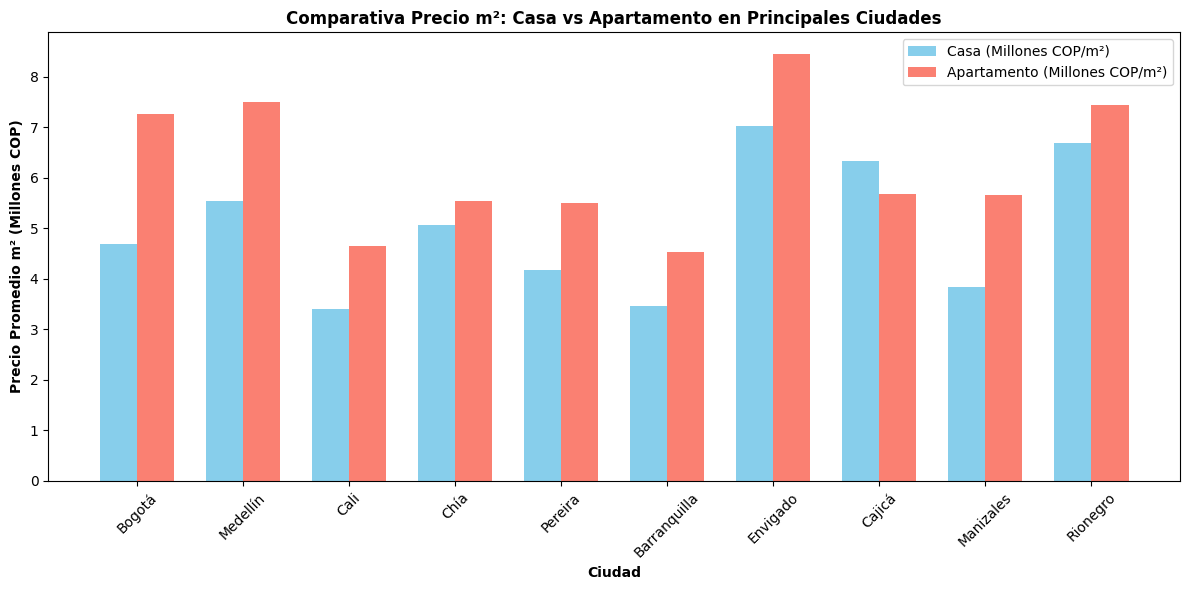

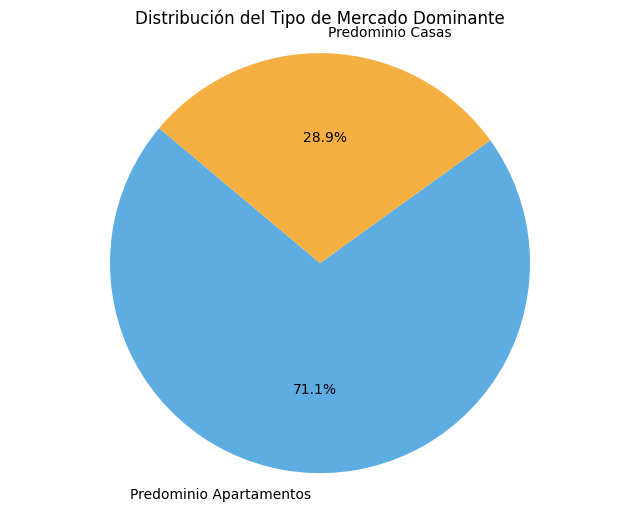

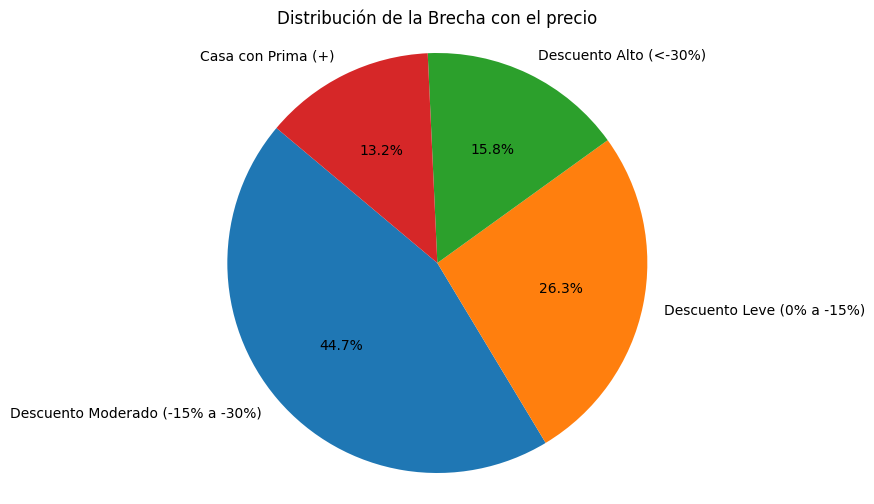

In [8]:
plt.figure(figsize=(12, 6))
top_ciudades = df_enriquecido.nlargest(10, 'n_si') # Top 10 según número de casas analizadas
bar_width = 0.35
x = range(len(top_ciudades))

plt.bar(x, top_ciudades['casa_cop_m2'] / 1e6, width=bar_width, label='Casa (Millones COP/m²)', color='skyblue')
plt.bar([p + bar_width for p in x], top_ciudades['apto_cop_m2'] / 1e6, width=bar_width, label='Apartamento (Millones COP/m²)', color='salmon')

plt.xlabel('Ciudad', fontweight='bold')
plt.ylabel('Precio Promedio m² (Millones COP)', fontweight='bold')
plt.title('Comparativa Precio m²: Casa vs Apartamento en Principales Ciudades', fontweight='bold')
plt.xticks([p + bar_width / 2 for p in x], top_ciudades['city'], rotation=45)
plt.legend()
plt.tight_layout()
plt.show()

#distribucion de las viviendas
conta=df_enriquecido['tipo_mercado_dominante'].value_counts()
plt.figure(figsize=(8,6))
plt.pie(
    conta,
    labels=conta.index,
    autopct='%1.1f%%',
    startangle=140,
    colors=['#5dade2','#f5b041']
)
plt.title('Distribución del Tipo de Mercado Dominante')
plt.axis('equal')               # Asegura que el gráfico sea un círculo perfecto
plt.show()
#brecha
conta=df_enriquecido['categoria_brecha_precio'].value_counts()
plt.figure(figsize=(8,6))
plt.pie(
    conta,
    labels=conta.index,
    autopct='%1.1f%%',
    startangle=140,    
)
plt.title('Distribución de la Brecha con el precio')
plt.axis('equal')               # Asegura que el gráfico sea un círculo perfecto
plt.show()



Con lo cual podemos ver que en los municipios cencanos a la las grandes capitales no siempre siguen la tendencia de precio o mantiene una prima alta como en el caso de medellin, donde sus municipios cercanos tiene un relacion de precio de metro cuadrado menor que bogota, a diferencia de medellin donde sus municipios cercanos tiene valores superiosres, como lo es envigado y rionegro donde se presentan precios superiores o iguales. Mostrando que en el mercado hay mas apartementos que casa y mayormente el descuento que se presenta es moderado (entre el 15% al 30%).

## ¿Existe una correlación directa entre el volumen de oferta analizado (n_si y n_no) y el nivel de precios del metro cuadrado? ##

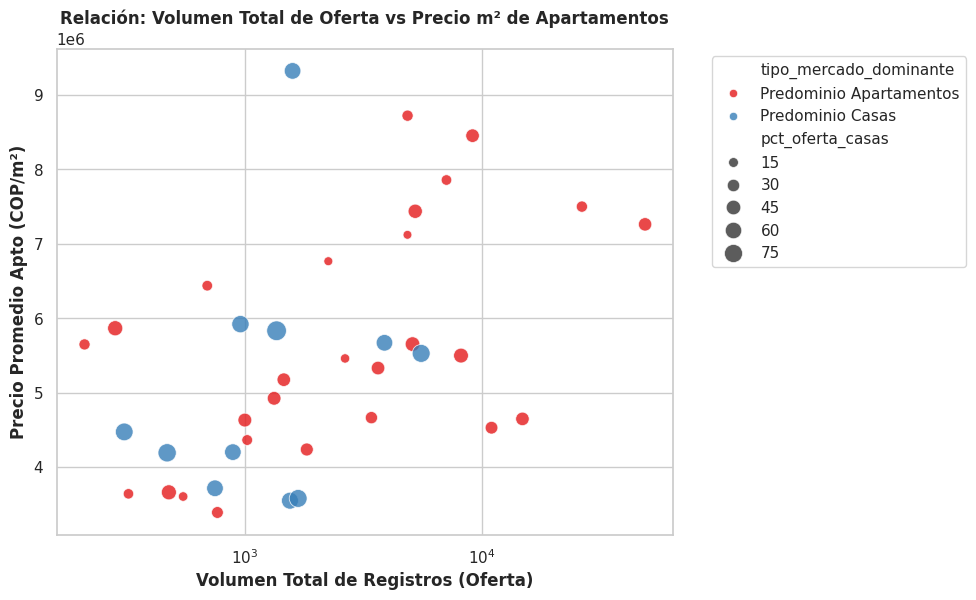

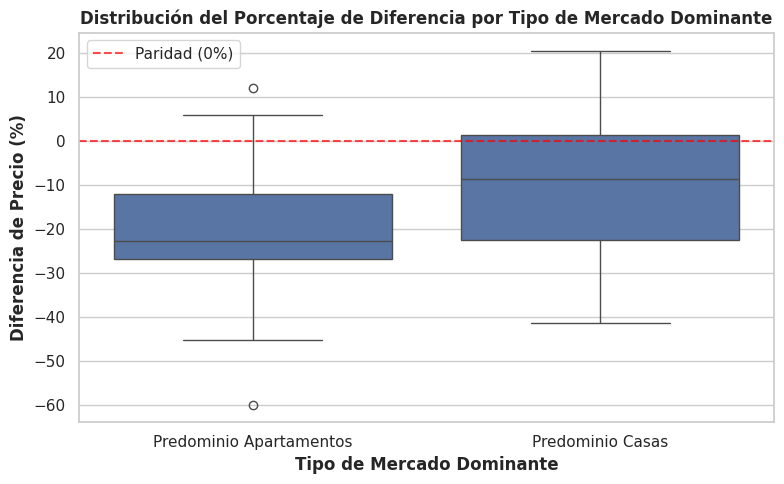

In [17]:
sns.set_theme(style="whitegrid")
plt.rcParams.update({'font.sans-serif': 'DejaVu Sans', 'font.family': 'sans-serif'})
# --- Dispersión Volumen vs Precio m² ---
plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=df_enriquecido, 
    x='total_registros', 
    y='apto_cop_m2', 
    size='pct_oferta_casas', 
    hue='tipo_mercado_dominante', 
    palette='Set1', 
    sizes=(40, 200), 
    alpha=0.8
)
plt.title('Relación: Volumen Total de Oferta vs Precio m² de Apartamentos', fontsize=12, fontweight='bold')
plt.xlabel('Volumen Total de Registros (Oferta)', fontweight='bold')
plt.ylabel('Precio Promedio Apto (COP/m²)', fontweight='bold')
plt.xscale('log') # Escala logarítmica debido a la diferencia de tamaño entre ciudades
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

# --- Boxplot - Diferencia % según Mercado Dominante ---
plt.figure(figsize=(8, 5))
sns.boxplot(
    data=df_enriquecido, 
    x='tipo_mercado_dominante', 
    y='diferencia_pct',   
)
plt.title('Distribución del Porcentaje de Diferencia por Tipo de Mercado Dominante', fontsize=12, fontweight='bold')
plt.xlabel('Tipo de Mercado Dominante', fontweight='bold')
plt.ylabel('Diferencia de Precio (%)', fontweight='bold')
plt.axhline(0, color='red', linestyle='--', alpha=0.7, label='Paridad (0%)')
plt.legend()
plt.tight_layout()
plt.show()

### Intereacción observada: ###
Al agrupar las ciudades según su tipología predominante (casas vs. apartamentos) frente a su porcentaje de diferencia de precios, los diagramas de caja revelan que en las plazas con fuerte vocación vertical, las casas sufren castigos de precio muy pronunciados (con descuentos de hasta el 60% en ciudades costeras como Santa Marta). En contraparte, en municipios donde la casa es el formato predominante o campestre, la balanza se invierte.

### Analisis ###
Existe una alta elasticidad de sustitución condicionada por la geografía urbana. En ciudades altamente densificadas, el apartamento es el estándar de valor refugio; mientras que en municipios intermedios o de expansión campestre, la casa adquiere una prima de valoración debido a la que las personas prefieen la privacidad y los espacios abiertos.

# ¿Cuál es la proporción general de costos a escala nacional entre ambas tipologías de vivienda? #

C:\Users\Usuario\AppData\Local\Temp\ipykernel_20136\1506897541.py:19: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


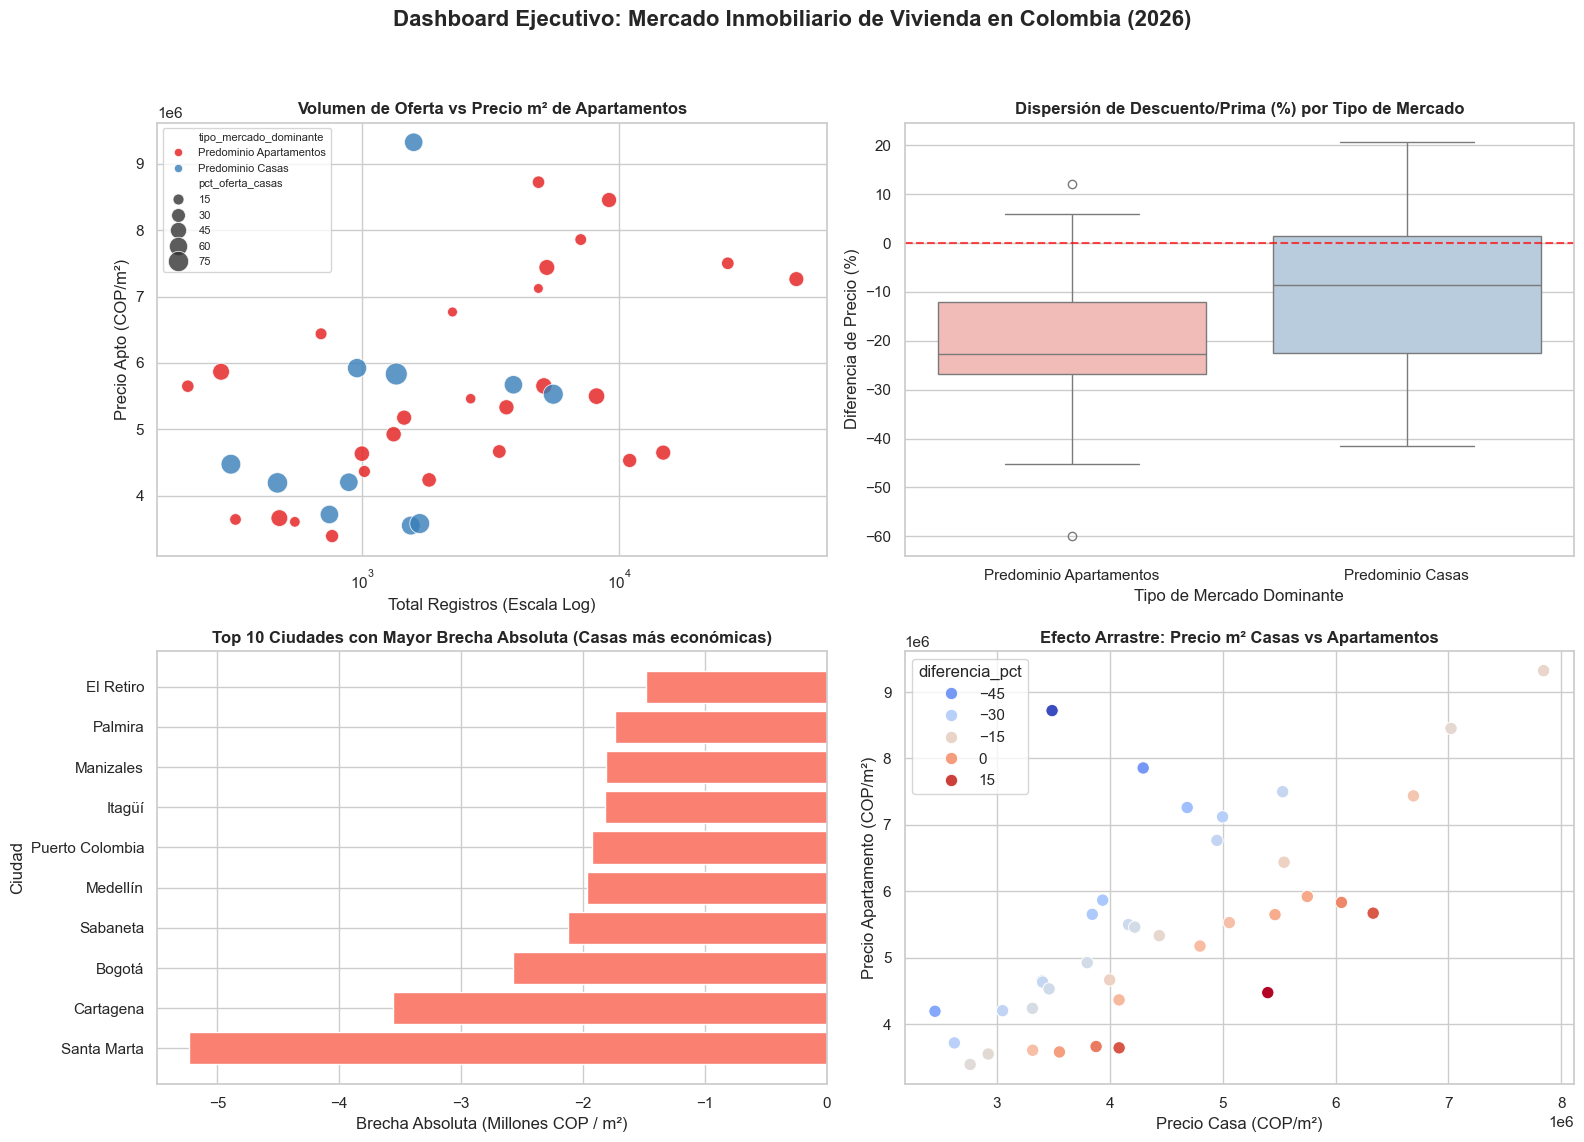

¡Dashboard exportado exitosamente como 'dashboard_inmobiliario_colombia_2026.png'!


In [20]:
# Configuración general de estilo
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(2, 2, figsize=(16, 12))
fig.suptitle('Dashboard Ejecutivo: Mercado Inmobiliario de Vivienda en Colombia (2026)', fontsize=16, fontweight='bold', y=0.98)

# 1. Gráfico Superior Izquierda: Volumen vs Precio Apto (Escala Log)
sns.scatterplot(
    data=df_enriquecido, x='total_registros', y='apto_cop_m2', 
    size='pct_oferta_casas', hue='tipo_mercado_dominante', 
    palette='Set1', sizes=(50, 250), alpha=0.8, ax=axes[0, 0]
)
axes[0, 0].set_title('Volumen de Oferta vs Precio m² de Apartamentos', fontweight='bold')
axes[0, 0].set_xlabel('Total Registros (Escala Log)')
axes[0, 0].set_ylabel('Precio Apto (COP/m²)')
axes[0, 0].set_xscale('log')
axes[0, 0].legend(loc='upper left', fontsize=8)

# 2. Gráfico Superior Derecha: Boxplot Diferencia % vs Mercado Dominante
sns.boxplot(
    data=df_enriquecido, x='tipo_mercado_dominante', y='diferencia_pct', 
    palette='Pastel1', ax=axes[0, 1]
)
axes[0, 1].set_title('Dispersión de Descuento/Prima (%) por Tipo de Mercado', fontweight='bold')
axes[0, 1].set_xlabel('Tipo de Mercado Dominante')
axes[0, 1].set_ylabel('Diferencia de Precio (%)')
axes[0, 1].axhline(0, color='red', linestyle='--', alpha=0.7)

# 3. Gráfico Inferior Izquierda: Top 10 Ciudades por Brecha Absoluta
top_brecha = df_enriquecido.sort_values(by='brecha_absoluta_cop', ascending=True).head(10)
axes[1, 0].barh(top_brecha['city'], top_brecha['brecha_absoluta_cop'] / 1e6, color='salmon')
axes[1, 0].set_title('Top 10 Ciudades con Mayor Brecha Absoluta (Casas más económicas)', fontweight='bold')
axes[1, 0].set_xlabel('Brecha Absoluta (Millones COP / m²)')
axes[1, 0].set_ylabel('Ciudad')

# 4. Gráfico Inferior Derecha: Correlación Casa vs Apto m²
sns.scatterplot(
    data=df_enriquecido, x='casa_cop_m2', y='apto_cop_m2', 
    hue='diferencia_pct', palette='coolwarm', s=80, ax=axes[1, 1]
)
axes[1, 1].set_title('Efecto Arrastre: Precio m² Casas vs Apartamentos', fontweight='bold')
axes[1, 1].set_xlabel('Precio Casa (COP/m²)')
axes[1, 1].set_ylabel('Precio Apartamento (COP/m²)')

plt.tight_layout(rect=[0, 0.03, 1, 0.95])
plt.savefig("dashboard_inmobiliario_colombia_2026.png", dpi=300)
plt.show()
print("¡Dashboard exportado exitosamente como 'dashboard_inmobiliario_colombia_2026.png'!")

### Cruce 3: Mapa de Calor de Correlaciones EstructuralesDinámica observada: ###

El análisis de correlación lineal entre las variables numéricas muestra una fuerte asociación positiva entre el precio del metro cuadrado de casas y el de apartamentos *($r > 0.8$)*. Esto demuestra un efecto de arrastre macroeconómico: si una ciudad es costosa en apartamentos, inevitablemente tenderá a ser costosa en casas, aunque mantenga un porcentaje de descuento relativo.

Analisis: Los precios de la finca raíz residencial en Colombia no operan en burbujas aisladas; están fuertemente anclados a la capacidad adquisitiva local y los costos de construcción de cada región, manteniendo una brecha porcentual estructural pero predecible.

### Cruce 4: Ranking de Brecha Absoluta de Precios (brecha_absoluta_cop) ###

Al calcular la distancia neta en pesos colombianos, las ciudades turísticas y costeras (Santa Marta y Cartagena) lideran la mayor pérdida de valor absoluto al comparar una casa frente a un apartamento. Por ejemplo, en Santa Marta la diferencia asciende a más de $5.2 millones de pesos menos por cada metro cuadrado de casa en comparación con un apartamento.

Analisis: Para el inversionista o comprador final, las ciudades costeras y de alta densidad vertical ofrecen una oportunidad de "ahorro por metro cuadrado" muy superior al optar por una casa, lo que representa una ventaja comparativa en términos de metros habitables adquiridos por cada peso invertido.

# RECOMENDACIONES #

## Estrategia de Inversion por Segun el Presupuesto ##
Si se busca mayor espacio por dinero invertido, los mercados de la costa y algunas zonas del eje cafetero ofrecen un mayor diferencial a favor d elas casas.

## Apuesta por lugares Campestres ##
Los municipios cercanos a Bogota y al Valle de Aburra  son o representan los mayores lugares donde la valorizacion de los apartamentos o propiedad horizontal se estan volviendoa activos de refugio de valor a largo plazo.

## Mitigacióon de riesgos ##
Aunque las casas en grandes ciudades o donde hay gran concentracion urbana tienen descuentos porcentuales altos su menor rotacion en el mercado (o menor volumen de oferta) tiene que ser tenida en cuenta en caso de re venta.